# Tutorial: Perceptron con Python y scikit-learn by Paola Michelle Ambriz Soto

---
## 1. Fundamentos teóricos del Perceptrón

### 1.1 Origen
El Perceptrón fue propuesto por Frank Rosenblatt a finales de los años 50, inspirado en el modelo de neurona artificial de McCulloch y Pitts (1943). Es uno de los primeros algoritmos de aprendizaje supervisado y el antecedente directo de las redes neuronales actuales.

### 1.2 La analogía con una neurona
| Neurona biológica | Perceptrón |
|---|---|
| Dendritas (reciben señales) | Entradas $x_1, x_2, \dots, x_d$ |
| Fuerza de cada sinapsis | Pesos $w_1, w_2, \dots, w_d$ |
| El cuerpo de la neurona integra las señales | Suma ponderada $z = \mathbf{w}\cdot\mathbf{x} + b$ |
| La neurona se "dispara" si supera un umbral | Función de activación escalón |
| Axón (señal de salida) | Salida $\hat{y} \in \{0, 1\}$ |

### 1.3 ¿Qué problema resuelve?
Un Perceptrón es un clasificador binario lineal: recibe las características de un objeto (por ejemplo, horas de estudio y asistencia de un alumno) y decide a cuál de dos clases pertenece (por ejemplo, aprueba o no aprueba).

### 1.4 La frontera de decisión
La ecuación $\mathbf{w}\cdot\mathbf{x} + b = 0$ describe un hiperplano que divide el espacio en dos regiones:
- con 2 características es una recta;
- con 3 características, un plano;
- con más, un hiperplano.

Los puntos de un lado se clasifican como clase 1 y los del otro lado como clase 0. El vector de pesos $\mathbf{w}$ es perpendicular a la frontera y apunta hacia la región de la clase 1; el sesgo $b$ desplaza la frontera.

### 1.5 ¿Cómo aprende?
El aprendizaje es iterativo y por corrección de errores:
1. Se inicializan los pesos (normalmente en cero).
2. Se recorre cada ejemplo de entrenamiento y se predice su clase.
3. Si la predicción es correcta, no se cambia nada.
4. Si es incorrecta, se mueve la frontera para acercarla a clasificar bien ese ejemplo: si era de la clase 1 y se predijo 0, el vector de pesos se mueve hacia $\mathbf{x}$; si era de la clase 0 y se predijo 1, se aleja de $\mathbf{x}$. El sesgo $b$ se ajusta en el mismo sentido.
5. Una pasada completa por los datos es una época. Se repite hasta que no haya errores o se alcance un máximo de épocas.

### 1.6 Datos linealmente separables y convergencia
Los datos son linealmente separables si existe al menos una recta (hiperplano) que deja todos los ejemplos de cada clase de su lado. El teorema de convergencia del Perceptrón (sección 2.4) garantiza que, si los datos de entrenamiento son linealmente separables, el algoritmo encuentra una frontera sin errores en un número finito de correcciones.

Si los datos no son linealmente separables, no existe ninguna frontera lineal que clasifique correctamente todas las observaciones, por lo que el algoritmo no puede alcanzar una época sin errores. En la práctica, una implementación como la de scikit-learn se detiene al llegar a un número máximo de épocas (max_iter) o cuando la pérdida deja de mejorar según tol; eso no significa que haya logrado clasificar perfectamente los datos.

### 1.7 Limitaciones
- Solo separa clases con una frontera lineal. El ejemplo clásico que no puede resolver es la función XOR (Minsky y Papert, 1969); se muestra en la sección 3.13.
- Si las clases se traslapan, no existe una frontera lineal sin errores y el resultado final depende del orden de los datos y del momento en que se detiene el entrenamiento (sección 3.11).
- No entrega probabilidades, solo una clase y un puntaje.
- Es sensible a la escala de las variables, por lo que conviene estandarizarlas.
- La solución no es única: distintas inicializaciones u órdenes de datos producen fronteras distintas que pueden clasificar igual de bien.

### 1.8 Importancia actual
Aunque es un modelo sencillo, el Perceptrón es el bloque básico de las redes neuronales multicapa: cada neurona de una red es, en esencia, una suma ponderada seguida de una función de activación. Para problemas parecidos, hoy suelen preferirse la regresión logística (que sí da probabilidades) o las máquinas de vectores de soporte.

---
## 2. Modelo matemático y analítico

### 2.1 Modelo
Para un ejemplo con $d$ características $\mathbf{x}=(x_1,\dots,x_d)$, el Perceptrón calcula el puntaje (suma ponderada con sesgo):

$$
z = \mathbf{w}\cdot\mathbf{x} + b = \sum_{j=1}^{d} w_j x_j + b
$$

y aplica la función escalón para obtener la clase predicha:

$$
\hat{y} = \begin{cases} 1 & \text{si } z > 0 \\ 0 & \text{si } z \leq 0 \end{cases}
$$

### 2.2 Frontera de decisión
La frontera es el conjunto de puntos donde $z=0$. Con dos características:

$$
w_1 x_1 + w_2 x_2 + b = 0 \quad\Longrightarrow\quad x_2 = -\frac{w_1}{w_2}\,x_1 - \frac{b}{w_2}
$$

(siempre que $w_2 \neq 0$). Es la recta que se dibujará en la sección 3.10.

### 2.3 Regla de aprendizaje
Para facilitar las fórmulas, las etiquetas se codifican como $t_i \in \{-1, +1\}$ (con $t_i=-1$ para la clase 0 y $t_i=+1$ para la clase 1). Se dice que el ejemplo $i$ está mal clasificado (o en la frontera) cuando su margen es no positivo:

$$
t_i\,(\mathbf{w}\cdot\mathbf{x}_i + b) \leq 0
$$

Con una tasa de aprendizaje $\eta > 0$, la regla del Perceptrón actualiza los parámetros solo cuando hay error:

$$
\mathbf{w} \leftarrow \mathbf{w} + \eta\, t_i\, \mathbf{x}_i, \qquad b \leftarrow b + \eta\, t_i
$$

La regla puede interpretarse como un paso de descenso de subgradiente estocástico (un ejemplo a la vez) sobre la pérdida por observación

$$
\ell_i(\mathbf{w},b)=\max\bigl(0,\,-t_i(\mathbf{w}\cdot\mathbf{x}_i+b)\bigr)
$$

El criterio del Perceptrón es la suma $L(\mathbf{w},b)=\sum_i \ell_i(\mathbf{w},b)$. Con el margen $m_i = t_i(\mathbf{w}\cdot\mathbf{x}_i+b)$:
- si $m_i>0$, la pérdida es 0 y no hay actualización;
- si $m_i<0$, la pérdida es $-m_i$ y un subgradiente respecto a $(\mathbf{w},b)$ es $-t_i(\mathbf{x}_i,1)$, lo que da exactamente la regla anterior;
- si $m_i=0$, la función no es diferenciable y hay varios subgradientes válidos; esta implementación (igual que scikit-learn, como confirma la sección 3.8) elige actualizar. Esa elección es necesaria para empezar: con $\mathbf{w}=\mathbf{0}$ y $b=0$ todos los márgenes valen 0 y, si no se actualizara cuando $m_i=0$, el algoritmo nunca se movería.

En scikit-learn, Perceptron() comparte implementación con SGDClassifier y equivale a SGDClassifier(loss="perceptron", eta0=1, learning_rate="constant", penalty=None).

> Observación sobre $\eta$: si los pesos y el sesgo empiezan en cero, $\eta>0$, los ejemplos se recorren en el mismo orden, no hay regularización y el entrenamiento dura el mismo número de épocas (sin un criterio de parada por tolerancia que dependa de la pérdida), multiplicar $\eta$ por una constante solo multiplica $\mathbf{w}$ y $b$ por esa constante, sin cambiar qué ejemplos se clasifican mal; por eso las predicciones no cambian. Fuera de esas condiciones (por ejemplo, con tol activo o con regularización), $\eta$ sí puede afectar el resultado. Se comprueba en la sección 3.11.

### 2.4 Teorema de convergencia (Novikoff, 1962)
Se aumenta cada ejemplo con un 1: $\tilde{\mathbf{x}}_i=(\mathbf{x}_i,1)$ y $\tilde{\mathbf{w}}=(\mathbf{w},b)$. Si existe un vector unitario $\tilde{\mathbf{w}}^*$ y un margen $\gamma>0$ tales que $t_i\,(\tilde{\mathbf{w}}^*\cdot\tilde{\mathbf{x}}_i)\geq\gamma$ para todo $i$ (datos linealmente separables), y $\lVert\tilde{\mathbf{x}}_i\rVert\leq R$ para todo $i$, entonces, partiendo de $\tilde{\mathbf{w}}=\mathbf{0}$, el algoritmo realiza a lo más

$$
\left(\frac{R}{\gamma}\right)^2
$$

correcciones. Si los datos no son separables, no hay garantía de convergencia.

### 2.5 Métricas de evaluación (clasificación)
Se define la matriz de confusión, con la clase 1 como la clase "positiva":

| | Predicho 0 | Predicho 1 |
|---|---|---|
| Real 0 | VN (verdaderos negativos) | FP (falsos positivos) |
| Real 1 | FN (falsos negativos) | VP (verdaderos positivos) |

| Métrica | Fórmula | Interpretación |
|---|---|---|
| Exactitud (accuracy) | $\dfrac{VP+VN}{VP+VN+FP+FN}$ | Proporción de predicciones correctas |
| Precisión | $\dfrac{VP}{VP+FP}$ | De los que se predijeron clase 1, cuántos lo eran |
| Exhaustividad (recall) | $\dfrac{VP}{VP+FN}$ | De los que son clase 1, cuántos se detectaron |
| F1 | $2\cdot\dfrac{\text{precisión}\cdot\text{recall}}{\text{precisión}+\text{recall}}$ | Media armónica de precisión y recall |

### 2.6 Implementación desde cero con NumPy
Antes de usar scikit-learn, se programa la regla de aprendizaje "a mano" y se prueba con la compuerta lógica AND, que es linealmente separable: la salida es 1 solo si $x_1=1$ y $x_2=1$.

In [1]:
import numpy as np  # Importa NumPy para álgebra lineal y arreglos numéricos, con el alias np


def entrenar_perceptron(X, t, eta=1.0, max_epocas=100):  # Define la función que entrena un Perceptrón (X: datos, t: etiquetas -1/+1, eta: tasa de aprendizaje)
    w = np.zeros(X.shape[1])  # Inicializa el vector de pesos en cero (un peso por característica)
    b = 0.0  # Inicializa el sesgo en cero
    errores_por_epoca = []  # Lista donde se guardará cuántas correcciones hubo en cada época
    for epoca in range(max_epocas):  # Recorre las épocas (pasadas completas por los datos) hasta el máximo permitido
        errores = 0  # Reinicia el contador de errores de esta época
        for xi, ti in zip(X, t):  # Recorre los ejemplos uno por uno, junto con su etiqueta
            if ti * (np.dot(w, xi) + b) <= 0:  # Comprueba si el margen es no positivo (ejemplo mal clasificado)
                w = w + eta * ti * xi  # Corrige los pesos: los mueve hacia xi (si ti=+1) o los aleja de xi (si ti=-1)
                b = b + eta * ti  # Corrige el sesgo con la misma regla
                errores += 1  # Cuenta una corrección en esta época
        errores_por_epoca.append(errores)  # Guarda el número de correcciones de esta época
        if errores == 0:  # Si en toda la época no hubo errores, el algoritmo ya convergió
            break  # Detiene el entrenamiento
    return w, b, errores_por_epoca  # Devuelve los pesos, el sesgo y el historial de errores


X_and = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)  # Define las 4 combinaciones de entrada de la compuerta AND
y_and = np.array([0, 0, 0, 1])  # Define la salida esperada de la compuerta AND (1 solo si ambas entradas son 1)
t_and = 2 * y_and - 1  # Convierte las etiquetas 0/1 a -1/+1, el formato que usa la regla de aprendizaje

w_and, b_and, err_and = entrenar_perceptron(X_and, t_and)  # Entrena el Perceptrón con los datos de la compuerta AND

print("Pesos aprendidos:", w_and, "| Sesgo:", b_and)  # Imprime los pesos y el sesgo finales
print("Errores por época:", err_and)  # Imprime las correcciones de cada época (la última debe ser 0)
print("Épocas necesarias:", len(err_and))  # Imprime cuántas épocas se necesitaron hasta converger
z_and = X_and @ w_and + b_and  # Calcula el puntaje z = w·x + b de cada entrada
print("Puntajes z:", z_and)  # Imprime los puntajes
print("Predicción (z > 0):", (z_and > 0).astype(int))  # Aplica el escalón: 1 si z > 0, 0 en caso contrario
print("Esperado:          ", y_and)  # Imprime la salida esperada para comparar

Pesos aprendidos: [3. 2.] | Sesgo: -4.0
Errores por época: [2, 3, 3, 2, 2, 3, 2, 1, 0]
Épocas necesarias: 9
Puntajes z: [-4. -2. -1.  1.]
Predicción (z > 0): [0 0 0 1]
Esperado:           [0 0 0 1]


Interpretación: el algoritmo converge a una frontera que clasifica correctamente las cuatro entradas y la última época no tiene errores, como garantiza el teorema de convergencia para datos separables. La frontera obtenida es $3x_1 + 2x_2 - 4 = 0$ (solo el punto $(1,1)$ queda del lado positivo).

Esta misma función entrenar_perceptron se reutilizará en la sección 3.8 (para verificar a scikit-learn) y en la 3.13 (para mostrar sus limitaciones).

---
## 3. Pipeline de Machine Learning

El flujo de trabajo completo que se sigue en este tutorial es:

```
Problema → Datos (CSV) → Análisis (EDA) → Scatter plot → Preparación (train/test + escalado)
        → Modelo → Entrenamiento → Verificación → Evaluación → Robustez → Predicción
```

### 3.0 Importación de librerías

In [2]:
import numpy as np  # Importa NumPy para operaciones numéricas
import pandas as pd  # Importa Pandas para manejar los datos en forma de tabla (DataFrame)
import matplotlib.pyplot as plt  # Importa Matplotlib para crear gráficas
from matplotlib.lines import Line2D  # Importa Line2D para construir una leyenda personalizada en la gráfica de la frontera

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate  # Importa funciones para dividir los datos y hacer validación cruzada
from sklearn.preprocessing import StandardScaler  # Importa el estandarizador de variables (media 0, desviación 1)
from sklearn.linear_model import Perceptron  # Importa el clasificador Perceptrón de scikit-learn
from sklearn.pipeline import Pipeline  # Importa Pipeline para encadenar escalado + modelo en un solo objeto
from sklearn.dummy import DummyClassifier  # Importa un clasificador de referencia que no aprende nada (línea base)
from sklearn.inspection import DecisionBoundaryDisplay  # Importa la utilidad para dibujar la frontera de decisión
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,  # Importa las métricas de clasificación
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)  # Importa la matriz de confusión, su gráfica y el reporte completo

plt.rcParams["figure.figsize"] = (8, 5)  # Define el tamaño por defecto de todas las gráficas (8 x 5 pulgadas)
plt.rcParams["axes.grid"] = True  # Activa la cuadrícula en todas las gráficas por defecto
SEED = 42  # Define una semilla fija que se usará en la división train/test, la validación cruzada y el modelo para que los resultados sean reproducibles

### 3.1 Definición del problema

Tipo de problema: aprendizaje supervisado, clasificación binaria.

Objetivo: a partir de dos características de un estudiante —las horas de estudio por semana y su porcentaje de asistencia— predecir si aprueba (1) o no aprueba (0) una materia.

Hipótesis: las dos clases pueden separarse razonablemente bien con una frontera lineal (una recta en el plano horas–asistencia), que es justo lo que puede aprender un Perceptrón.

### 3.2 Recolección de datos (importar un archivo CSV)

Los datos se importan desde un archivo CSV (dataset_perceptron.csv) con pd.read_csv. Cada fila es un estudiante y el archivo tiene tres columnas:

| Columna | Descripción |
|---|---|
| horas_estudio | Horas de estudio por semana (variable de entrada) |
| asistencia | Porcentaje de asistencia a clase (variable de entrada) |
| aprueba | Variable objetivo: 1 si aprueba, 0 si no aprueba |

> Los datos son sintéticos: se generaron con dos grupos de 150 estudiantes cada uno (distribuciones normales con medias distintas para cada clase) y con un ligero traslape entre ellos, para simular un caso realista en el que las clases son casi separables pero no perfectamente.

Los datos se importan desde un archivo CSV cargado en mi repositorio de github, se subió el dataset a mi repo, se hizo click en raw para tener los datos crudos y github nos proporcionó un link (el cual declaré abajo en RUTA_CSV), de esta manera no se necesita subir nada en el google colab ya que el dataset está en línea. El dataset está cargado en mi repositorio de github "Hands-on 4" como dataset_perceptron.csv

In [3]:
RUTA_CSV = "https://raw.githubusercontent.com/Michelleas31/Hands-on-4/refs/heads/main/dataset_perceptron.csv"  # URL Raw del CSV en mi repo
df = pd.read_csv(RUTA_CSV)  # Lee el archivo CSV y lo convierte en un DataFrame de Pandas
print("Archivo cargado correctamente desde:", RUTA_CSV)  # Confirma que la lectura fue exitosa

Archivo cargado correctamente desde: https://raw.githubusercontent.com/Michelleas31/Hands-on-4/refs/heads/main/dataset_perceptron.csv


### 3.3 Descripción y análisis del dataset (EDA)

El Análisis Exploratorio de Datos (EDA) permite conocer la estructura de los datos, detectar valores faltantes, revisar el balance de clases y comparar las variables entre clases antes de modelar.

In [4]:
print("Dimensiones del dataset (filas, columnas):", df.shape)  # Imprime cuántas filas y columnas tiene el DataFrame
print("\nPrimeras 5 filas:")  # Imprime un encabezado para la tabla siguiente
display(df.head())  # Muestra las primeras 5 filas del dataset para inspeccionarlo visualmente

Dimensiones del dataset (filas, columnas): (300, 3)

Primeras 5 filas:


,horas_estudio,asistencia,aprueba
0,15.61,77.48,1
1,14.39,86.88,1
2,9.81,100.00,1
3,3.87,82.13,0
4,17.01,91.17,1


In [5]:
print("Información general del DataFrame:")  # Imprime un encabezado descriptivo
df.info()  # Muestra los tipos de dato de cada columna y la cantidad de valores no nulos

Información general del DataFrame:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   horas_estudio  300 non-null    float64
 1   asistencia     300 non-null    float64
 2   aprueba        300 non-null    int64  
dtypes: float64(2), int64(1)
memory usage: 7.2 KB


In [6]:
print("Estadísticos descriptivos:")  # Imprime un encabezado descriptivo
display(df.describe())  # Muestra conteo, media, desviación estándar, mínimo, cuartiles y máximo de cada columna

Estadísticos descriptivos:


,horas_estudio,asistencia,aprueba
count,300.000000,300.000000,300.000000
mean,9.897167,78.848400,0.500000
std,4.653214,11.128923,0.500835
min,0.670000,53.660000,0.000000
25%,5.940000,70.730000,0.000000
50%,9.650000,79.065000,0.500000
75%,13.745000,87.540000,1.000000
max,21.260000,100.000000,1.000000


In [7]:
print("Valores nulos por columna:")  # Imprime un encabezado descriptivo
print(df.isnull().sum())  # Cuenta los valores faltantes (NaN) de cada columna; se espera 0 en todas
print("\nFilas duplicadas:", df.duplicated().sum())  # Cuenta cuántas filas están repetidas en el dataset

print("\nBalance de clases (conteo):")  # Imprime un encabezado descriptivo
print(df["aprueba"].value_counts().sort_index())  # Cuenta cuántos estudiantes hay en cada clase
print("\nBalance de clases (proporción):")  # Imprime un encabezado descriptivo
print(df["aprueba"].value_counts(normalize=True).sort_index().round(3))  # Calcula la proporción de cada clase sobre el total

Valores nulos por columna:
horas_estudio    0
asistencia       0
aprueba          0
dtype: int64

Filas duplicadas: 0

Balance de clases (conteo):
aprueba
0    150
1    150
Name: count, dtype: int64

Balance de clases (proporción):
aprueba
0    0.5
1    0.5
Name: proportion, dtype: float64


In [8]:
print("Media y desviación estándar de cada variable, por clase:")  # Imprime un encabezado descriptivo
display(df.groupby("aprueba")[["horas_estudio", "asistencia"]].agg(["mean", "std"]).round(2))  # Calcula la media y la desviación estándar de cada variable separando por clase

Media y desviación estándar de cada variable, por clase:


horas_estudio       asistencia      
                 mean   std       mean   std
aprueba                                     
0                5.87  2.14      70.18  6.99
1               13.92  2.51      87.51  6.96

Interpretación del EDA:
- El dataset tiene 300 observaciones, 2 variables de entrada numéricas y 1 variable objetivo binaria, sin valores nulos ni duplicados.
- Las clases están balanceadas (150 y 150), así que la exactitud (accuracy) es una métrica razonable y el clasificador de referencia que siempre predice la clase mayoritaria acertaría solo ≈ 50 %.
- Los estudiantes que aprueban tienen, en promedio, más horas de estudio y más asistencia. Las dos variables están en escalas muy distintas (horas: 0 a ~21; asistencia: ~54 a 100), lo que justifica estandarizarlas antes de entrenar.
- La asistencia máxima es exactamente 100 en varios estudiantes: es un efecto de recortar los valores al 100 % al generar los datos (un porcentaje no puede pasar de 100), por eso aparecen varios puntos alineados en el borde superior del scatter plot.

### 3.4 Scatter plot (diagrama de dispersión)

Graficar los datos coloreados por clase permite ver si una frontera lineal es plausible. Además de la dispersión conjunta, se muestran los histogramas de cada variable por clase.

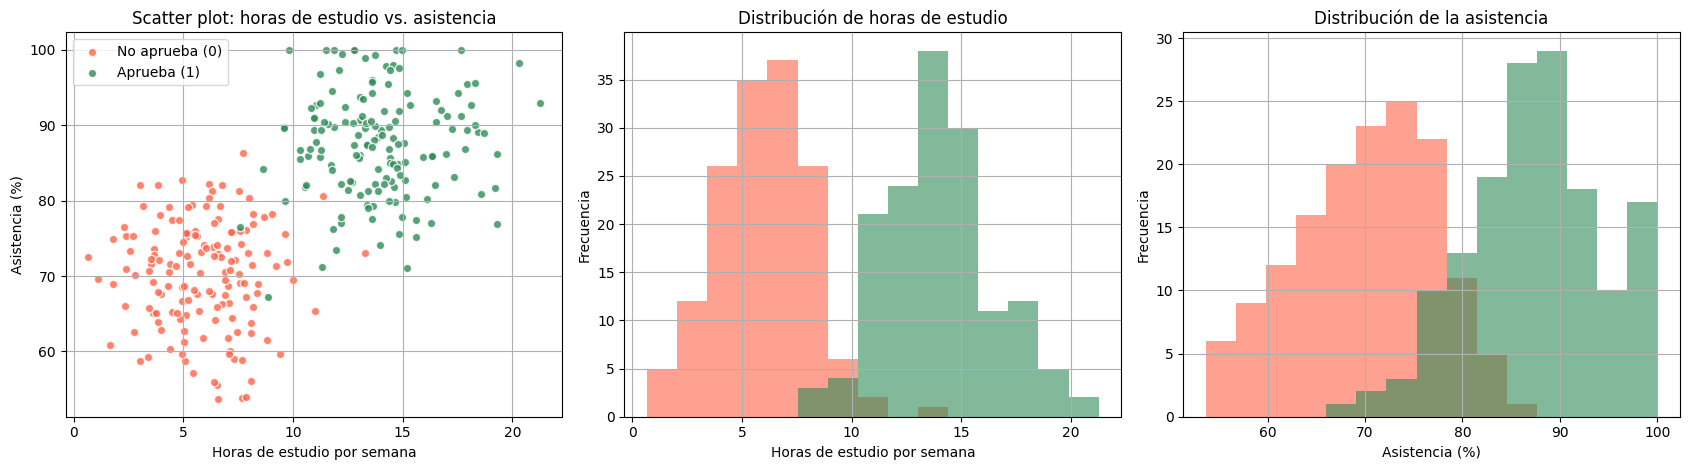

In [9]:
colores = {0: "tomato", 1: "seagreen"}  # Define un color para cada clase: rojo para 0 y verde para 1
nombres = {0: "No aprueba (0)", 1: "Aprueba (1)"}  # Define el nombre legible de cada clase para las leyendas

bins_horas = np.histogram_bin_edges(df["horas_estudio"], bins=15)  # Calcula una sola vez los bordes de las barras de horas con todos los datos, para que ambas clases usen los mismos intervalos
bins_asistencia = np.histogram_bin_edges(df["asistencia"], bins=15)  # Calcula una sola vez los bordes de las barras de asistencia con todos los datos

fig, ejes = plt.subplots(1, 3, figsize=(17, 4.8))  # Crea una figura con tres paneles lado a lado

for clase in (0, 1):  # Recorre cada clase para dibujarla con su color
    sub = df[df["aprueba"] == clase]  # Selecciona solo los estudiantes de esa clase
    ejes[0].scatter(sub["horas_estudio"], sub["asistencia"], color=colores[clase], edgecolor="white", alpha=0.8, label=nombres[clase])  # Panel 1: dibuja los puntos de la clase en el plano horas vs asistencia
    ejes[1].hist(sub["horas_estudio"], bins=bins_horas, color=colores[clase], alpha=0.6, label=nombres[clase])  # Panel 2: histograma de horas de estudio de la clase
    ejes[2].hist(sub["asistencia"], bins=bins_asistencia, color=colores[clase], alpha=0.6, label=nombres[clase])  # Panel 3: histograma de asistencia de la clase

ejes[0].set_title("Scatter plot: horas de estudio vs. asistencia")  # Título del panel 1
ejes[0].set_xlabel("Horas de estudio por semana")  # Etiqueta del eje horizontal del panel 1
ejes[0].set_ylabel("Asistencia (%)")  # Etiqueta del eje vertical del panel 1
ejes[0].legend()  # Muestra la leyenda de las clases en el panel 1
ejes[1].set_title("Distribución de horas de estudio")  # Título del panel 2
ejes[1].set_xlabel("Horas de estudio por semana")  # Etiqueta del eje horizontal del panel 2
ejes[1].set_ylabel("Frecuencia")  # Etiqueta del eje vertical del panel 2
ejes[2].set_title("Distribución de la asistencia")  # Título del panel 3
ejes[2].set_xlabel("Asistencia (%)")  # Etiqueta del eje horizontal del panel 3
ejes[2].set_ylabel("Frecuencia")  # Etiqueta del eje vertical del panel 3

plt.tight_layout()  # Ajusta los espacios para que no se encimen los elementos
plt.show()  # Renderiza la figura en el notebook

Observación: en el plano horas–asistencia se distinguen dos nubes de puntos, una arriba a la derecha (aprueban) y otra abajo a la izquierda (no aprueban), y se podría trazar una recta que las separe casi por completo, aunque en la zona intermedia hay un ligero traslape de algunos puntos. Esto indica que las clases son casi linealmente separables: un Perceptrón es un modelo apropiado, pero no se espera una exactitud perfecta: las clases no son perfectamente separables (se verifica en la sección 3.8).

### 3.5 Preparación de los datos (separación train / test y escalado)

1) Separación. Los datos se dividen en:
- Entrenamiento (80 %): se usa para ajustar el modelo.
- Prueba (20 %): datos que el modelo nunca vio, reservados para la evaluación final (sección 3.9).

Se usa stratify=y para que ambos conjuntos conserven la misma proporción de cada clase.

2) Escalado. El Perceptrón es sensible a la escala de las variables: una variable con valores grandes (asistencia, ≈ 50–100) dominaría a una con valores pequeños (horas, ≈ 0–20). Por eso se estandariza cada variable (media 0 y desviación 1):

$$
x_j^{\text{std}} = \frac{x_j - \mu_j}{\sigma_j}
$$

La media $\mu$ y la desviación $\sigma$ deben calcularse solo con los datos de entrenamiento para no filtrar información del conjunto de prueba (data leakage). Al incluir el escalador dentro de un Pipeline (sección 3.6), scikit-learn lo hace automáticamente, también dentro de la validación cruzada.

In [10]:
columnas = ["horas_estudio", "asistencia"]  # Define las columnas que se usarán como características de entrada
X = df[columnas].values  # Extrae las características como matriz 2D de forma (300, 2)
y = df["aprueba"].values  # Extrae la variable objetivo como arreglo 1D con valores 0 y 1

X_train, X_test, y_train, y_test = train_test_split(  # Divide los datos en subconjuntos de entrenamiento y prueba
    X, y,  # Pasa las entradas X y las salidas y que se van a dividir
    test_size=0.2,  # Reserva el 20 % de los datos para la prueba
    random_state=SEED,  # Fija la semilla para que la división sea siempre la misma
    stratify=y,  # Mantiene la misma proporción de clases en entrenamiento y prueba
)  # Cierra la llamada a train_test_split

print("Tamaño de entrenamiento:", X_train.shape[0], "| clase 0:", (y_train == 0).sum(), "| clase 1:", (y_train == 1).sum())  # Muestra el tamaño y la distribución de clases del conjunto de entrenamiento
print("Tamaño de prueba:       ", X_test.shape[0], "| clase 0:", (y_test == 0).sum(), "| clase 1:", (y_test == 1).sum())  # Muestra el tamaño y la distribución de clases del conjunto de prueba

Tamaño de entrenamiento: 240 | clase 0: 120 | clase 1: 120
Tamaño de prueba:        60 | clase 0: 30 | clase 1: 30


In [11]:
escalador_demo = StandardScaler().fit(X_train)  # Calcula media y desviación de cada variable usando SOLO los datos de entrenamiento (con fines demostrativos)
print("Media de entrenamiento (horas, asistencia):     ", escalador_demo.mean_.round(2))  # Muestra la media calculada de cada variable
print("Desv. estándar de entrenamiento (horas, asist.):", escalador_demo.scale_.round(2))  # Muestra la desviación estándar calculada de cada variable
X_train_esc_demo = escalador_demo.transform(X_train)  # Aplica la estandarización a los datos de entrenamiento
print("Media tras escalar:", X_train_esc_demo.mean(axis=0).round(3))  # Verifica que la media de cada variable escalada sea ≈ 0
print("Desv. estándar tras escalar:", X_train_esc_demo.std(axis=0).round(3))  # Verifica que la desviación estándar de cada variable escalada sea ≈ 1

Media de entrenamiento (horas, asistencia):      [ 9.9  78.81]
Desv. estándar de entrenamiento (horas, asist.): [ 4.6  11.01]
Media tras escalar: [ 0. -0.]
Desv. estándar tras escalar: [1. 1.]


### 3.6 Selección del modelo

El modelo es un Pipeline de dos pasos:

1. StandardScaler(): estandariza las variables (usando solo datos de entrenamiento).
2. Perceptron(): clasificador lineal entrenado con la regla del Perceptrón.

Hiperparámetros principales de Perceptron (se dejan los valores por defecto, salvo la semilla):

| Hiperparámetro | Valor por defecto | Qué controla |
|---|---|---|
| max_iter | 1000 | Número máximo de épocas |
| tol | 1e-3 | Criterio de parada: se detiene si la pérdida deja de mejorar |
| eta0 | 1.0 | Tasa de aprendizaje $\eta$ (bajo las condiciones de la sección 2.3, no cambia las predicciones) |
| shuffle | True | Mezcla los datos en cada época |
| penalty | None | Regularización (ninguna por defecto) |
| random_state | — | Semilla de la mezcla de datos (se fija para reproducibilidad) |

In [12]:
def crear_modelo(random_state=SEED, **kwargs):  # Define una función que construye el pipeline (sin entrenar); kwargs permite cambiar hiperparámetros del Perceptrón
    return Pipeline([  # Devuelve un Pipeline: una secuencia de pasos que se ejecutan en orden
        ("escalador", StandardScaler()),  # Paso 1: estandariza las variables con la media y desviación del entrenamiento
        ("perceptron", Perceptron(random_state=random_state, **kwargs)),  # Paso 2: clasificador Perceptrón con la semilla indicada
    ])  # Cierra la definición del Pipeline


print(crear_modelo())  # Imprime la estructura del pipeline para verificar los pasos

Pipeline(steps=[('escalador', StandardScaler()),
                ('perceptron', Perceptron(random_state=42))])


### 3.7 Entrenamiento del modelo

Al llamar fit, el pipeline estandariza los datos de entrenamiento y el Perceptrón recorre los ejemplos por épocas, corrigiendo pesos y sesgo en cada error, hasta que se cumple el criterio de parada.

Los coeficientes que se muestran están en el espacio escalado. Para interpretar la frontera en las unidades originales (horas y porcentaje), se transforman con:

$$
w_j^{\text{orig}} = \frac{w_j}{\sigma_j}, \qquad b^{\text{orig}} = b - \sum_j \frac{w_j\,\mu_j}{\sigma_j}
$$

In [13]:
modelo = crear_modelo()  # Construye el pipeline final con la semilla fija
modelo.fit(X_train, y_train)  # Entrena el pipeline: estandariza los datos y ajusta el Perceptrón

esc = modelo.named_steps["escalador"]  # Obtiene el escalador ya ajustado dentro del pipeline
perc = modelo.named_steps["perceptron"]  # Obtiene el Perceptrón ya entrenado dentro del pipeline

print("Épocas realizadas:", perc.n_iter_)  # Imprime cuántas épocas ejecutó el algoritmo antes de detenerse
print("Pesos en espacio escalado (w1, w2):", perc.coef_[0].round(4))  # Imprime los pesos aprendidos para las variables estandarizadas
print("Sesgo en espacio escalado (b):     ", perc.intercept_[0].round(4))  # Imprime el sesgo aprendido

w_orig = perc.coef_[0] / esc.scale_  # Convierte los pesos al espacio de las variables originales (divide entre la desviación estándar)
b_orig = perc.intercept_[0] - np.sum(perc.coef_[0] * esc.mean_ / esc.scale_)  # Convierte el sesgo al espacio original
print("\nFrontera en unidades originales:")  # Imprime un encabezado descriptivo
print(f"  {w_orig[0]:.4f} * horas + {w_orig[1]:.4f} * asistencia + ({b_orig:.4f}) = 0")  # Imprime la ecuación de la recta de decisión w1*x1 + w2*x2 + b = 0

print("\nExactitud en entrenamiento:", round(modelo.score(X_train, y_train), 4))  # Calcula y muestra la exactitud sobre los datos de entrenamiento

Épocas realizadas: 8
Pesos en espacio escalado (w1, w2): [2.3881 1.2424]
Sesgo en espacio escalado (b):      -1.0

Frontera en unidades originales:
  0.5188 * horas + 0.1129 * asistencia + (-15.0319) = 0

Exactitud en entrenamiento: 0.9583


Interpretación: los dos pesos son positivos, así que más horas de estudio y más asistencia aumentan el puntaje hacia la clase "aprueba". En unidades originales, la pendiente de la frontera es $-w_1/w_2 \approx -0.5188/0.1129 \approx -4.6$: para mantener el mismo puntaje sobre la frontera, una hora adicional de estudio por semana permite ≈ 4.6 puntos porcentuales menos de asistencia. Es una relación matemática entre las dos variables en esa recta, no una relación causal. La exactitud en entrenamiento (≈ 0.958) muestra que el modelo no clasifica perfectamente los datos de entrenamiento, algo esperado porque las clases se traslapan.

### 3.8 Verificación con la implementación propia (NumPy)

Para comprobar que el modelo matemático de la sección 2 es el que usa scikit-learn, se entrena la función entrenar_perceptron (sección 2.6) con los mismos datos estandarizados y se compara con Perceptron de scikit-learn.

Para que la comparación sea exacta, el Perceptrón de scikit-learn se configura de forma determinista: sin mezclar los datos (shuffle=False), sin criterio de parada por tolerancia (tol=None), con un número fijo de épocas y sin regularización. En esas condiciones, ambos recorren los datos en el mismo orden y hacen exactamente las mismas correcciones.

> Este modelo de verificación es distinto del modelo final de la sección 3.7 (que mezcla los datos y usa criterio de parada); sirve solo para validar las ecuaciones.

In [14]:
EPOCAS = 50  # Define un número fijo de épocas para ambas implementaciones
Z_train = esc.transform(X_train)  # Estandariza los datos de entrenamiento con el escalador ya ajustado
t_train = 2 * y_train - 1  # Convierte las etiquetas 0/1 a -1/+1 para la implementación propia

w_man, b_man, errores_epoca = entrenar_perceptron(Z_train, t_train, eta=1.0, max_epocas=EPOCAS)  # Entrena con la función propia (NumPy) sobre los datos estandarizados

perc_det = Perceptron(shuffle=False, tol=None, max_iter=EPOCAS, eta0=1.0, penalty=None)  # Crea un Perceptrón de scikit-learn determinista: sin mezclar, sin tolerancia y sin regularización
perc_det.fit(Z_train, y_train)  # Entrena el Perceptrón de scikit-learn con los mismos datos estandarizados

comparacion = pd.DataFrame({  # Crea una tabla para comparar ambas implementaciones
    "Parámetro": ["w1 (horas)", "w2 (asistencia)", "b (sesgo)"],  # Nombres de los parámetros
    "NumPy (propia)": np.append(w_man, b_man),  # Valores obtenidos con la implementación propia
    "scikit-learn": np.append(perc_det.coef_[0], perc_det.intercept_[0]),  # Valores obtenidos con scikit-learn
})  # Cierra la creación de la tabla
display(comparacion.round(5))  # Muestra la tabla con 5 decimales

iguales = np.allclose(w_man, perc_det.coef_[0]) and np.allclose(b_man, perc_det.intercept_[0])  # Verifica numéricamente que los pesos y el sesgo coinciden
print("¿Coinciden ambas implementaciones?", iguales)  # Imprime el resultado de la comprobación
print("Épocas ejecutadas por la implementación propia:", len(errores_epoca))  # Imprime cuántas épocas ejecutó la función propia (si no hay convergencia, llega al máximo)
print("Errores en las primeras 10 épocas:", errores_epoca[:10])  # Imprime las correcciones de las primeras 10 épocas

,Parámetro,NumPy (propia),scikit-learn
0,w1 (horas),2.36571,2.36571
1,w2 (asistencia),0.15988,0.15988
2,b (sesgo),0.00000,0.00000


¿Coinciden ambas implementaciones? True
Épocas ejecutadas por la implementación propia: 50
Errores en las primeras 10 épocas: [14, 8, 8, 11, 9, 8, 8, 10, 8, 9]


Interpretación: los pesos y el sesgo de la implementación propia coinciden con los de scikit-learn: en este experimento, ambas implementaciones aplican la misma regla de actualización. Esto valida la consistencia entre las dos, no constituye por sí solo una prueba general del modelo matemático.

Además, el número de correcciones no llega a cero en ninguna de las 50 épocas ejecutadas. Para no depender solo de ese resultado, se comprueba directamente si existe una frontera lineal sin errores. Si los datos fueran separables con un margen positivo, siempre se podrían reescalar $\mathbf{w}$ y $b$ para que $t_i(\mathbf{w}\cdot\mathbf{x}_i+b)\geq 1$ para todo $i$. Se plantea esa condición como un problema de programación lineal de factibilidad: si no tiene solución, ninguna recta clasifica bien todos los ejemplos.

In [15]:
from scipy.optimize import linprog  # Importa el resolvedor de programación lineal de SciPy

n_var = Z_train.shape[1] + 1  # Calcula el número de incógnitas: un peso por característica más el sesgo
A_ub = -(t_train[:, None] * np.column_stack([Z_train, np.ones(len(Z_train))]))  # Construye las restricciones -t_i * [x_i, 1] (una fila por ejemplo)
b_ub = -np.ones(len(Z_train))  # Fija el lado derecho en -1, es decir, exige t_i * (w·x_i + b) >= 1 para todos los ejemplos
res = linprog(c=np.zeros(n_var), A_ub=A_ub, b_ub=b_ub, bounds=[(None, None)] * n_var)  # Busca pesos y sesgo que cumplan todas las restricciones (no hay nada que minimizar: solo se pregunta si existe solución)
print("¿Existe una recta que clasifique bien todos los ejemplos de entrenamiento?", res.status == 0)  # status 0 indica que el problema tiene solución; cualquier otro valor indica que no

¿Existe una recta que clasifique bien todos los ejemplos de entrenamiento? False


Resultado: el problema no tiene solución, así que el conjunto de entrenamiento no es linealmente separable. Por el teorema de convergencia, ninguna época puede terminar sin errores, y eso es lo que se observó en las 50 épocas.

### 3.9 Evaluación del modelo (métricas)

El modelo final (sección 3.7) se evalúa sobre el conjunto de prueba, que no participó en el entrenamiento. Se comparan también las métricas de entrenamiento y las de un clasificador de referencia (DummyClassifier, que siempre predice la clase mayoritaria) para saber cuánto aporta realmente el modelo.

In [16]:
y_pred_train = modelo.predict(X_train)  # Genera las predicciones del modelo sobre los datos de entrenamiento
y_pred_test = modelo.predict(X_test)  # Genera las predicciones del modelo sobre los datos de prueba (no vistos)

base = DummyClassifier(strategy="most_frequent")  # Crea el clasificador de referencia que siempre predice la clase más frecuente
base.fit(X_train, y_train)  # "Entrena" la línea base (solo memoriza la clase mayoritaria)
y_pred_base = base.predict(X_test)  # Genera las predicciones de la línea base sobre los datos de prueba


def evaluar(y_real, y_pred):  # Define una función que calcula las métricas de clasificación (clase 1 = positiva)
    return {  # Devuelve las métricas en un diccionario
        "Exactitud": accuracy_score(y_real, y_pred),  # Proporción de predicciones correctas
        "Precisión": precision_score(y_real, y_pred, zero_division=0),  # De los predichos como 1, cuántos eran 1
        "Recall": recall_score(y_real, y_pred, zero_division=0),  # De los que eran 1, cuántos se detectaron
        "F1": f1_score(y_real, y_pred, zero_division=0),  # Media armónica de precisión y recall
    }  # Cierra el diccionario


metricas = pd.DataFrame({  # Crea una tabla comparativa de métricas
    "Perceptrón (entrenamiento)": evaluar(y_train, y_pred_train),  # Métricas del modelo con los datos de entrenamiento
    "Perceptrón (prueba)": evaluar(y_test, y_pred_test),  # Métricas del modelo con los datos de prueba
    "Línea base (prueba)": evaluar(y_test, y_pred_base),  # Métricas del clasificador de referencia con los datos de prueba
})  # Cierra la creación de la tabla
display(metricas.round(4))  # Muestra la tabla con 4 decimales

cm = confusion_matrix(y_test, y_pred_test)  # Calcula la matriz de confusión sobre el conjunto de prueba
display(pd.DataFrame(cm, index=["Real 0", "Real 1"], columns=["Predicho 0", "Predicho 1"]))  # Muestra la matriz de confusión como tabla con etiquetas
print("\nReporte de clasificación (prueba):")  # Imprime un encabezado descriptivo
print(classification_report(y_test, y_pred_test, target_names=["No aprueba (0)", "Aprueba (1)"], digits=3))  # Imprime precisión, recall y F1 de cada clase

,Perceptrón (entrenamiento),Perceptrón (prueba),Línea base (prueba)
Exactitud,0.9583,0.9667,0.5
Precisión,0.9911,1.0000,0.0
Recall,0.9250,0.9333,0.0
F1,0.9569,0.9655,0.0


,Predicho 0,Predicho 1
Real 0,30,0
Real 1,2,28



Reporte de clasificación (prueba):
                precision    recall  f1-score   support

No aprueba (0)      0.938     1.000     0.968        30
   Aprueba (1)      1.000     0.933     0.966        30

      accuracy                          0.967        60
     macro avg      0.969     0.967     0.967        60
  weighted avg      0.969     0.967     0.967        60



Interpretación de las métricas:
- En el conjunto de prueba el modelo obtiene una exactitud de ≈ 0.967 (58 de 60 correctos). La matriz de confusión muestra 0 falsos positivos y 2 falsos negativos: nunca predijo "aprueba" para alguien que no aprobó (precisión = 1.0), pero dejó pasar a 2 estudiantes que sí aprobaron (recall ≈ 0.933).
- La exactitud de entrenamiento (≈ 0.958) y la de prueba (≈ 0.967) son similares; que la de prueba sea ligeramente mayor es variación de muestreo (60 observaciones), no una señal de que el modelo "mejore" con datos nuevos. No se observa una diferencia preocupante entre entrenamiento y prueba, aunque una sola partición no basta para descartar el sobreajuste de forma definitiva; la validación cruzada de la sección 3.11 refuerza la conclusión. Además, estos resultados provienen de un dataset sintético de 300 observaciones: son demostrativos y no permiten afirmar que un sistema real alcanzaría la misma exactitud.
- Frente a la línea base (exactitud 0.5, porque las clases están balanceadas y siempre predice la misma clase), el Perceptrón sí aprendió la relación entre las variables y la clase. La línea base tiene precisión, recall y F1 iguales a 0 porque nunca predice la clase 1.
- El conjunto de prueba tiene solo 60 observaciones: cada error cambia la exactitud en ≈ 1.7 puntos porcentuales, así que las métricas de prueba son aproximadas. La sección 3.11 cuantifica esa variabilidad.

### 3.10 Visualización: frontera de decisión, matriz de confusión y errores por época

Se grafican tres cosas:
1. La frontera de decisión aprendida, dibujada en las unidades originales junto con los datos de entrenamiento y de prueba.
2. La matriz de confusión del conjunto de prueba.
3. El número de correcciones por época de la implementación propia (sección 3.8), para ver el comportamiento de convergencia.

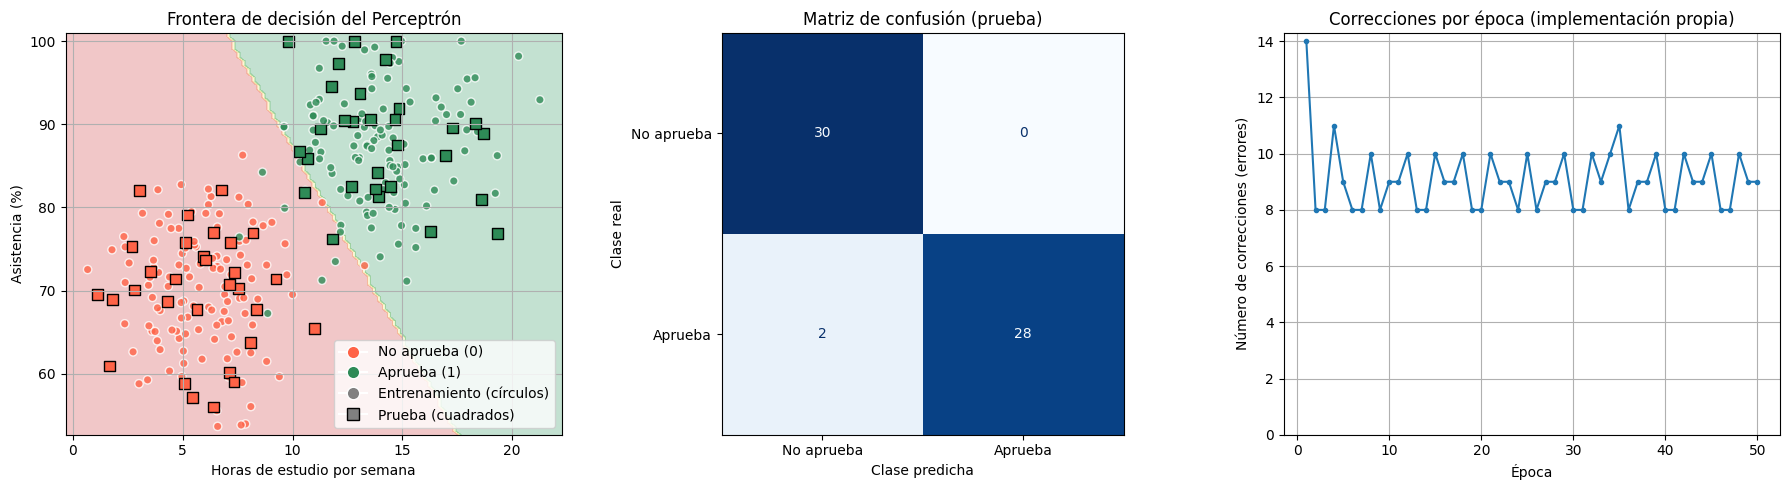

In [17]:
fig, ejes = plt.subplots(1, 3, figsize=(18, 5))  # Crea una figura con tres paneles lado a lado

DecisionBoundaryDisplay.from_estimator(  # Dibuja las regiones de decisión del modelo sobre una malla de puntos
    modelo, X, response_method="predict", cmap="RdYlGn", alpha=0.25, ax=ejes[0],  # Usa el pipeline completo, colorea cada región según la clase predicha y dibuja en el panel 1
    xlabel="Horas de estudio por semana", ylabel="Asistencia (%)",  # Etiquetas de los ejes
)  # Cierra la llamada a DecisionBoundaryDisplay
ejes[0].scatter(X_train[:, 0], X_train[:, 1], c=[colores[k] for k in y_train], edgecolor="white", alpha=0.8)  # Dibuja los puntos de entrenamiento coloreados por su clase real
ejes[0].scatter(X_test[:, 0], X_test[:, 1], c=[colores[k] for k in y_test], edgecolor="black", marker="s", s=60)  # Dibuja los puntos de prueba como cuadrados con borde negro
ejes[0].set_title("Frontera de decisión del Perceptrón")  # Título del panel 1
manijas = [  # Define manualmente las entradas de la leyenda: dos por color de clase y dos por tipo de conjunto
    Line2D([0], [0], marker="o", color="w", markerfacecolor=colores[0], markeredgecolor="white", markersize=9, label="No aprueba (0)"),  # Entrada para el color de la clase 0
    Line2D([0], [0], marker="o", color="w", markerfacecolor=colores[1], markeredgecolor="white", markersize=9, label="Aprueba (1)"),  # Entrada para el color de la clase 1
    Line2D([0], [0], marker="o", color="w", markerfacecolor="gray", markeredgecolor="white", markersize=9, label="Entrenamiento (círculos)"),  # Entrada para la forma de los puntos de entrenamiento
    Line2D([0], [0], marker="s", color="w", markerfacecolor="gray", markeredgecolor="black", markersize=9, label="Prueba (cuadrados)"),  # Entrada para la forma de los puntos de prueba
]  # Cierra la lista de entradas de la leyenda
ejes[0].legend(handles=manijas, loc="lower right")  # Muestra la leyenda personalizada en la esquina inferior derecha

ConfusionMatrixDisplay.from_predictions(  # Dibuja la matriz de confusión a partir de las etiquetas reales y las predichas
    y_test, y_pred_test, display_labels=["No aprueba", "Aprueba"], cmap="Blues", ax=ejes[1], colorbar=False,  # Usa el conjunto de prueba y dibuja en el panel 2
)  # Cierra la llamada a ConfusionMatrixDisplay
ejes[1].set_title("Matriz de confusión (prueba)")  # Título del panel 2
ejes[1].set_xlabel("Clase predicha")  # Etiqueta del eje horizontal del panel 2 en español
ejes[1].set_ylabel("Clase real")  # Etiqueta del eje vertical del panel 2 en español
ejes[1].grid(False)  # Quita la cuadrícula del panel 2 para que no tape los números

ejes[2].plot(range(1, len(errores_epoca) + 1), errores_epoca, marker="o", markersize=3)  # Dibuja el número de correcciones en cada época de la implementación propia
ejes[2].set_title("Correcciones por época (implementación propia)")  # Título del panel 3
ejes[2].set_xlabel("Época")  # Etiqueta del eje horizontal del panel 3
ejes[2].set_ylabel("Número de correcciones (errores)")  # Etiqueta del eje vertical del panel 3
ejes[2].set_ylim(bottom=0)  # Fija el origen del eje vertical en 0 para ver cuán lejos está de converger

plt.tight_layout()  # Ajusta los espacios para que no se encimen los elementos
plt.show()  # Renderiza la figura

Interpretación:
- Frontera: el Perceptrón traza una recta que separa las dos nubes de puntos; los pocos errores se concentran donde las clases se traslapan, cerca de la frontera.
- Matriz de confusión: los números fuera de la diagonal son los errores en el conjunto de prueba.
- Correcciones por época: esta curva corresponde a la variante determinista de la sección 3.8 (no al modelo final, que mezcla los datos), pero ilustra el mismo fenómeno: no baja a cero: tras la primera época, el número de correcciones fluctúa entre ≈ 8 y 11 y nunca se alcanza una época sin errores. Como los datos no son linealmente separables (sección 3.8), eso es lo esperado. Por eso el modelo final depende de en qué época se detiene el entrenamiento y del orden de los datos, lo que se examina a continuación.

### 3.11 Robustez: validación cruzada, semillas y tasa de aprendizaje

Como el conjunto de prueba es pequeño (60 observaciones) y las clases se traslapan, una sola cifra de exactitud puede ser engañosa. Se examinan tres aspectos:

a) Validación cruzada estratificada de 5 particiones sobre el conjunto de entrenamiento (el conjunto de prueba no se toca): es la estimación principal del desempeño y de su variación entre particiones.

b) Sensibilidad a la semilla (orden aleatorio de los datos en cada época): se entrena el mismo modelo con 10 semillas distintas y se observa cuánto varía la exactitud de prueba. Es un análisis de sensibilidad al orden de entrenamiento, no una estimación independiente de la capacidad de generalización, porque todos esos modelos se evalúan con el mismo conjunto de prueba. No se elige "la mejor semilla" a partir de ese conjunto, porque eso sesgaría la evaluación.

c) Efecto de la tasa de aprendizaje $\eta$: según la sección 2.3, bajo ciertas condiciones (pesos iniciales en cero, mismo orden de datos, sin regularización y el mismo número de épocas) escalar $\eta$ solo escala los pesos y no cambia las predicciones. Por eso aquí se usa tol=None y un número fijo de épocas.

In [18]:
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)  # Define la validación cruzada de 5 particiones conservando la proporción de clases
cv = cross_validate(crear_modelo(), X_train, y_train, cv=kf, scoring=["accuracy", "f1"])  # Entrena y evalúa un pipeline nuevo en cada partición (el escalador se ajusta solo con los datos de entrenamiento de esa partición)
resumen_cv = pd.DataFrame({  # Crea una tabla con el resultado de cada partición
    "Partición": range(1, 6),  # Número de partición
    "Exactitud": cv["test_accuracy"],  # Exactitud en la partición de validación
    "F1": cv["test_f1"],  # F1 en la partición de validación
})  # Cierra la creación de la tabla
display(resumen_cv.round(4))  # Muestra la tabla con 4 decimales
print(f"Exactitud CV: {cv['test_accuracy'].mean():.4f} ± {cv['test_accuracy'].std(ddof=1):.4f}")  # Imprime la media y la desviación estándar de la exactitud entre particiones
print(f"F1 CV:        {cv['test_f1'].mean():.4f} ± {cv['test_f1'].std(ddof=1):.4f}")  # Imprime la media y la desviación estándar del F1 entre particiones

,Partición,Exactitud,F1
0,1,1.0000,1.0000
1,2,0.9583,0.9583
2,3,0.9375,0.9412
3,4,0.9792,0.9787
4,5,0.9583,0.9565


Exactitud CV: 0.9667 ± 0.0238
F1 CV:        0.9670 ± 0.0228


In [19]:
exactitudes_semilla = []  # Lista donde se guardará la exactitud de prueba para cada semilla
for semilla in range(10):  # Recorre 10 semillas distintas (0 a 9)
    m = crear_modelo(random_state=semilla)  # Construye un pipeline con esa semilla
    m.fit(X_train, y_train)  # Entrena el pipeline con el conjunto de entrenamiento
    exactitudes_semilla.append(m.score(X_test, y_test))  # Guarda la exactitud en el conjunto de prueba

exactitudes_semilla = np.array(exactitudes_semilla)  # Convierte la lista en un arreglo de NumPy para calcular estadísticos
print("Exactitud de prueba por semilla:", exactitudes_semilla.round(3))  # Imprime la exactitud de prueba obtenida con cada semilla
print(f"Media = {exactitudes_semilla.mean():.4f} | Desv. est. = {exactitudes_semilla.std(ddof=1):.4f} | mín = {exactitudes_semilla.min():.4f} | máx = {exactitudes_semilla.max():.4f}")  # Imprime media, desviación estándar, mínimo y máximo

Exactitud de prueba por semilla: [1.    1.    0.967 0.967 1.    0.983 0.917 1.    0.983 1.   ]
Media = 0.9817 | Desv. est. = 0.0266 | mín = 0.9167 | máx = 1.0000


In [20]:
filas_eta = []  # Lista donde se guardará una fila de resultados por cada valor de eta
pred_ref = crear_modelo(eta0=1.0, tol=None, max_iter=30).fit(X_train, y_train).predict(X_test)  # Calcula las predicciones de referencia con eta = 1 (sin criterio de parada por tolerancia)
for eta in [0.01, 0.1, 1.0, 10.0]:  # Recorre varios valores de la tasa de aprendizaje
    m = crear_modelo(eta0=eta, tol=None, max_iter=30).fit(X_train, y_train)  # Entrena un pipeline con ese eta, mismas épocas y misma semilla
    p = m.predict(X_test)  # Obtiene las predicciones sobre el conjunto de prueba
    filas_eta.append({  # Guarda los resultados de este eta en un diccionario
        "eta0": eta,  # Valor de la tasa de aprendizaje
        "w1 (escalado)": m.named_steps["perceptron"].coef_[0, 0],  # Primer peso aprendido (en espacio escalado)
        "w2 (escalado)": m.named_steps["perceptron"].coef_[0, 1],  # Segundo peso aprendido (en espacio escalado)
        "Exactitud prueba": m.score(X_test, y_test),  # Exactitud en el conjunto de prueba
        "¿Mismas predicciones que eta=1?": bool(np.array_equal(p, pred_ref)),  # Verifica si las predicciones son idénticas a las de eta = 1
    })  # Cierra el diccionario
display(pd.DataFrame(filas_eta).round(4))  # Muestra la tabla con 4 decimales

,eta0,w1 (escalado),w2 (escalado),Exactitud prueba,¿Mismas predicciones que eta=1?
0,0.01,0.0218,0.0120,1.0,True
1,0.10,0.2177,0.1200,1.0,True
2,1.00,2.1767,1.2000,1.0,True
3,10.00,21.7672,12.0003,1.0,True


Interpretación:
- Validación cruzada: la exactitud es ≈ 0.967 ± 0.024 entre particiones (F1 ≈ 0.967), coherente con lo observado en prueba, y es la estimación principal del desempeño y es más estable que una sola evaluación.
- Semillas: al cambiar solo el orden aleatorio de los datos, la exactitud de prueba varía entre ≈ 0.917 y 1.0 (media ≈ 0.98 con las 10 semillas). Es un análisis de sensibilidad al orden de entrenamiento, no una segunda estimación independiente (todos los modelos usan el mismo conjunto de prueba). Muestra que, como las clases se traslapan, el resultado depende del orden de los datos; por eso conviene reportar un rango o un promedio y no una sola cifra.
- Tasa de aprendizaje: los pesos crecen proporcionalmente a $\eta$ (el peso con $\eta=10$ es 1000 veces el de $\eta=0.01$), pero las predicciones son idénticas. En estas condiciones, $\eta$ no es un hiperparámetro útil para ajustar en el Perceptrón. (La exactitud de 1.0 de esta tabla difiere de la del modelo final, ≈ 0.967, porque aquí se entrenan 30 épocas sin criterio de parada: el momento en que se detiene el entrenamiento también influye en el resultado, por la falta de convergencia.)

### 3.12 Predicción con datos nuevos

Una vez validado, el modelo se usa para clasificar estudiantes nuevos. decision_function devuelve el puntaje $z=\mathbf{w}\cdot\mathbf{x}+b$ (en el espacio escalado): es positivo si se predice clase 1 y negativo si se predice clase 0. No es una probabilidad: el Perceptrón no tiene predict_proba.

In [21]:
X_nuevos = np.array([[4, 60], [10, 75], [16, 92], [12, 65]], dtype=float)  # Define 4 estudiantes nuevos: [horas de estudio, asistencia]
clases_nuevas = modelo.predict(X_nuevos)  # Predice la clase de cada estudiante nuevo con el modelo final
puntajes = modelo.decision_function(X_nuevos)  # Calcula el puntaje z de cada estudiante (positivo = clase 1)

for xi, ci, zi in zip(X_nuevos, clases_nuevas, puntajes):  # Recorre cada estudiante con su clase y su puntaje
    etiqueta = "Aprueba" if ci == 1 else "No aprueba"  # Convierte la clase numérica en texto
    print(f"Horas = {xi[0]:4.1f} | Asistencia = {xi[1]:5.1f} %  ->  {etiqueta:10s} (puntaje z = {zi:7.3f})")  # Imprime la predicción con formato alineado

Horas =  4.0 | Asistencia =  60.0 %  ->  No aprueba (puntaje z =  -6.185)
Horas = 10.0 | Asistencia =  75.0 %  ->  No aprueba (puntaje z =  -1.379)
Horas = 16.0 | Asistencia =  92.0 %  ->  Aprueba    (puntaje z =   3.652)
Horas = 12.0 | Asistencia =  65.0 %  ->  No aprueba (puntaje z =  -1.470)


### 3.13 Limitaciones del Perceptrón: el problema XOR

La función XOR devuelve 1 cuando las dos entradas son distintas y 0 cuando son iguales. Es el ejemplo clásico de un problema no linealmente separable, y esto es una propiedad matemática del problema, no un resultado de unas cuantas épocas de entrenamiento. Si existiera una frontera $w_1x_1+w_2x_2+b$ que clasificara bien las cuatro entradas (clase 1 si el puntaje es positivo), se tendría:

$$
b \leq 0 \ (0,0), \qquad w_1+w_2+b \leq 0 \ (1,1), \qquad w_2+b > 0 \ (0,1), \qquad w_1+b > 0 \ (1,0)
$$

Sumando las dos primeras, $w_1+w_2+2b\leq 0$; sumando las dos últimas, $w_1+w_2+2b>0$. Es una contradicción, así que no existe tal frontera. Se entrena la misma función entrenar_perceptron sobre XOR para ver su comportamiento.

Una forma de resolverlo sin cambiar el algoritmo es agregar una característica no lineal, el producto $x_1 x_2$. En ese nuevo espacio de 3 dimensiones, los datos sí son separables. (Es la misma idea de crear características polinomiales de la regresión polinomial.)

In [22]:
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)  # Define las 4 combinaciones de entrada de la compuerta XOR
y_xor = np.array([0, 1, 1, 0])  # Define la salida de XOR: 1 solo cuando las entradas son distintas
t_xor = 2 * y_xor - 1  # Convierte las etiquetas 0/1 a -1/+1

w_x, b_x, err_x = entrenar_perceptron(X_xor, t_xor, max_epocas=50)  # Entrena el Perceptrón con XOR (máximo 50 épocas)
print("XOR con las 2 entradas originales:")  # Imprime un encabezado descriptivo
print("  Épocas ejecutadas:", len(err_x), "(el máximo permitido es 50)")  # Imprime cuántas épocas se ejecutaron: si llega a 50, no convergió
print("  Errores por época (primeras 8):", err_x[:8])  # Imprime las correcciones de las primeras épocas
print("  ¿Convergió (última época sin errores)?", err_x[-1] == 0)  # Indica si el algoritmo terminó sin errores

X_xor3 = np.column_stack([X_xor, X_xor[:, 0] * X_xor[:, 1]])  # Agrega una tercera característica: el producto x1 * x2
w_x3, b_x3, err_x3 = entrenar_perceptron(X_xor3, t_xor, max_epocas=50)  # Entrena el Perceptrón con las 3 características
print("\nXOR con la característica adicional x1*x2:")  # Imprime un encabezado descriptivo
print("  Épocas ejecutadas:", len(err_x3), "| ¿Convergió?", err_x3[-1] == 0)  # Indica si ahora sí convergió
print("  Predicciones:", ((X_xor3 @ w_x3 + b_x3) > 0).astype(int), "| Esperado:", y_xor)  # Compara las predicciones con la salida esperada de XOR

XOR con las 2 entradas originales:
  Épocas ejecutadas: 50 (el máximo permitido es 50)
  Errores por época (primeras 8): [4, 4, 4, 4, 4, 4, 4, 4]
  ¿Convergió (última época sin errores)? False

XOR con la característica adicional x1*x2:
  Épocas ejecutadas: 12 | ¿Convergió? True
  Predicciones: [0 1 1 0] | Esperado: [0 1 1 0]


Interpretación: con las dos entradas originales, XOR no admite ninguna frontera lineal que clasifique correctamente sus cuatro observaciones (demostración anterior), y la implementación ejecutada no alcanza una época sin errores. Al añadir la característica $x_1x_2$, los datos se vuelven linealmente separables en el espacio transformado y el Perceptrón logra clasificarlos correctamente. Esta limitación es la que motivó el desarrollo de las redes neuronales multicapa, que pueden aprender fronteras no lineales combinando varias neuronas.

---
## 4. Conclusiones

1. El Perceptrón es un clasificador binario lineal que aprende corrigiendo sus errores: calcula una suma ponderada, aplica un escalón y, cuando se equivoca, mueve la frontera con la regla $\mathbf{w}\leftarrow\mathbf{w}+\eta t_i\mathbf{x}_i$.
2. La implementación propia en NumPy coincidió exactamente con Perceptron de scikit-learn al usar la misma configuración determinista. Esto valida la consistencia entre ambas implementaciones en este experimento.
3. Los resultados ilustran el teorema de convergencia: con la compuerta AND (separable) se alcanza una época sin errores; con el dataset de estudiantes y con XOR no existe una frontera lineal sin errores (se comprobó por programación lineal y por demostración), por lo que no se puede obtener una clasificación lineal perfecta.
4. El EDA y el scatter plot mostraron dos nubes de puntos casi separables por una recta y variables en escalas distintas, por lo que se estandarizaron dentro de un Pipeline para evitar fuga de información.
5. La validación cruzada (exactitud ≈ 0.967 ± 0.024) es la estimación principal del desempeño; el análisis por semillas es un diagnóstico de la sensibilidad al orden de los datos. Se evaluó además contra una línea base. Como el dataset es sintético y el conjunto de prueba es pequeño (60 observaciones), los resultados son demostrativos y conviene reportar un rango o un promedio, no una sola cifra.
6. En las condiciones del experimento (pesos iniciales en cero, mismo orden, sin regularización y mismo número de épocas), modificar $\eta$ escala los parámetros sin alterar las predicciones.
7. Limitaciones: solo produce fronteras lineales, no entrega probabilidades y es sensible a la escala y al orden de los datos. Para problemas con traslape se suelen preferir la regresión logística o las SVM, y para fronteras no lineales, redes multicapa o características no lineales.

---
## 5. Referencias
- Rosenblatt, F. (1958). The Perceptron: A Probabilistic Model for Information Storage and Organization in the Brain. Psychological Review, 65(6), 386–408. https://doi.org/10.1037/h0042519
- Novikoff, A. B. J. (1962). On convergence proofs on perceptrons. Symposium on the Mathematical Theory of Automata, 12, 615–622.
- Minsky, M., Papert, S. (1969). Perceptrons: An Introduction to Computational Geometry. MIT Press.
- Hastie, T., Tibshirani, R., Friedman, J. The Elements of Statistical Learning (2.ª ed.), cap. 4.5: Separating Hyperplanes. Springer, 2009.
- scikit-learn. Perceptron. https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Perceptron.html
- scikit-learn. Stochastic Gradient Descent (SGDClassifier). https://scikit-learn.org/stable/modules/sgd.html
- scikit-learn. StandardScaler. https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html
- scikit-learn. Metrics and scoring: quantifying the quality of predictions. https://scikit-learn.org/stable/modules/model_evaluation.html